In [1]:
from pathlib import Path
import xarray as xr
import pandas as pd
from neuralhydrology.evaluation.metrics import (
    mean_peak_timing,
    missed_peaks,
    mean_absolute_percentage_peak_error,
)
import matplotlib.pyplot as plt
from xarray import DataArray
import numpy as np

from scipy import signal
from neuralhydrology.datautils import utils
from neuralhydrology.evaluation.metrics import _validate_inputs, _mask_valid

from scipy import stats


In [2]:
# ------------- Paths -------------
time_series = Path("/inputs/data_updated_2/time_series") #US
basins_file = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/1_531_caravan_vs_camels/2_531_basin.txt") #US
us_output = Path("./peak_metrics/530_united_states") #US
us_output.mkdir(parents=True, exist_ok=True)
caravan_attributes_dir = Path("/inputs/data_updated_2/attributes/attributes_caravan.csv")
camels_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/1_531_caravan_vs_camels/ensemble_metrics/camels_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")


In [3]:
with open(basins_file, "r") as f:
    basins = f.read().splitlines()

len(basins)

531

In [4]:
# Date range filter
DATE_START = "1989-10-01"
DATE_END   = "2014-09-30"

In [6]:
PRECIP_COLS_US = {
    "camels": "camels_precipitation",
}
GAUGE_COL_US = "streamflow"

results_us = []

for basin_name in basins:
    basin_id = basin_name

    try:
        ds = xr.open_dataset(time_series / f"{basin_name}.nc")
        ds = ds.sel(date=slice(DATE_START, DATE_END))

        obs: DataArray = ds[GAUGE_COL_US]

        for product_name, col in PRECIP_COLS_US.items():
            if col not in ds:
                print(f"  Skipping {product_name} for {basin_id}: column not found")
                continue

            sim: DataArray = ds[col]
            row = {"basin": basin_id, "product": product_name}

            try:
                corr, p_value = stats.pearsonr(sim.values, obs.values)
                row["correlation"] = corr
                row["correlation_pvalue"] = p_value
            except Exception as e:
                row["correlation"] = np.nan
                row["correlation_pvalue"] = np.nan
                print(f"  correlation failed ({basin_id}, {product_name}): {e}")

            try:
                max_lag = 365
                lags = np.arange(0, max_lag + 1)
                correlations = []
                
                for lag in lags:
                    if lag > 0:
                        sim_slice = sim.values[:-lag]
                        obs_slice = obs.values[lag:]
                    else:
                        sim_slice = sim.values
                        obs_slice = obs.values
                    
                    # Remove NaNs from both arrays
                    valid_idx = ~(np.isnan(sim_slice) | np.isnan(obs_slice))
                    sim_clean = sim_slice[valid_idx]
                    obs_clean = obs_slice[valid_idx]
                    
                    # Only compute if we have enough valid data
                    if len(sim_clean) > 1:
                        corr = np.corrcoef(sim_clean, obs_clean)[0, 1]
                        correlations.append(corr)
                    else:
                        correlations.append(np.nan)
                
                correlations = np.array(correlations)
                best_lag = lags[np.nanargmax(np.abs(correlations))]
                best_corr = correlations[best_lag]
                
                row["best_lag"] = best_lag
                row["correlation_at_best_lag"] = best_corr
            except Exception as e:
                row["best_lag"] = np.nan
                row["correlation_at_best_lag"] = np.nan
                print(f"  lag correlation failed ({basin_id}, {product_name}): {e}")

            results_us.append(row)

    except Exception as e:
        print(f"Skipping {basin_id}: {e}")

df_results_us = pd.DataFrame(results_us)

In [7]:
df_results_us

,basin,product,correlation,correlation_pvalue,best_lag,correlation_at_best_lag
0,camels_01022500,camels,0.296760,5.016380e-185,1,0.424156
1,camels_01031500,camels,0.393651,0.000000e+00,0,0.393651
2,camels_01047000,camels,0.468733,0.000000e+00,0,0.468733
3,camels_01052500,camels,0.351736,3.739100e-264,0,0.351736
4,camels_01054200,camels,0.552618,0.000000e+00,0,0.552618
...,...,...,...,...,...,...
526,camels_11482500,camels,0.640946,0.000000e+00,1,0.660798
527,camels_11522500,camels,0.462100,0.000000e+00,1,0.469986
528,camels_11523200,camels,0.344812,2.899095e-253,0,0.344812
529,camels_11528700,camels,0.540760,0.000000e+00,1,0.543374


In [7]:
attributes = pd.read_csv(caravan_attributes_dir)
attributes.head()

,gauge_id,aridity_ERA5_LAND,aridity_FAO_PM,frac_snow,high_prec_dur,high_prec_freq,low_prec_dur,low_prec_freq,moisture_index_ERA5_LAND,moisture_index_FAO_PM,p_mean,pet_mean_ERA5_LAND,pet_mean_FAO_PM,seasonality_ERA5_LAND,seasonality_FAO_PM
0,camels_01013500,3.763929,0.492557,0.374538,1.105263,0.047433,2.835099,0.586037,-0.598445,0.537406,3.175454,11.952184,1.564091,0.849594,0.972252
1,camels_01022500,4.539418,0.580916,0.335440,1.083770,0.056674,3.238029,0.638741,-0.716118,0.409718,3.203837,14.543556,1.861159,0.458492,1.187054
2,camels_01030500,4.263635,0.532879,0.316130,1.093123,0.052225,3.029760,0.613210,-0.667997,0.471618,3.184069,13.575707,1.696722,0.632035,1.119152
3,camels_01031500,3.947586,0.510585,0.306273,1.093185,0.053799,3.149326,0.623614,-0.646806,0.495480,3.289056,12.983833,1.679343,0.667906,1.097448
4,camels_01047000,3.694839,0.501584,0.299063,1.100430,0.052498,3.239731,0.626215,-0.628010,0.512243,3.275610,12.102852,1.642993,0.679129,1.047740


In [9]:
df_results_us = df_results_us.merge(
    attributes[['gauge_id', 'frac_snow']], 
    left_on='basin', 
    right_on='gauge_id', 
    how='left'
)

df_results_us.head()

,basin,product,correlation,correlation_pvalue,best_lag,correlation_at_best_lag,gauge_id,frac_snow
0,camels_01022500,camels,0.296760,5.016380e-185,1,0.424156,camels_01022500,0.335440
1,camels_01031500,camels,0.393651,0.000000e+00,0,0.393651,camels_01031500,0.306273
2,camels_01047000,camels,0.468733,0.000000e+00,0,0.468733,camels_01047000,0.299063
3,camels_01052500,camels,0.351736,3.739100e-264,0,0.351736,camels_01052500,0.368406
4,camels_01054200,camels,0.552618,0.000000e+00,0,0.552618,camels_01054200,0.374272


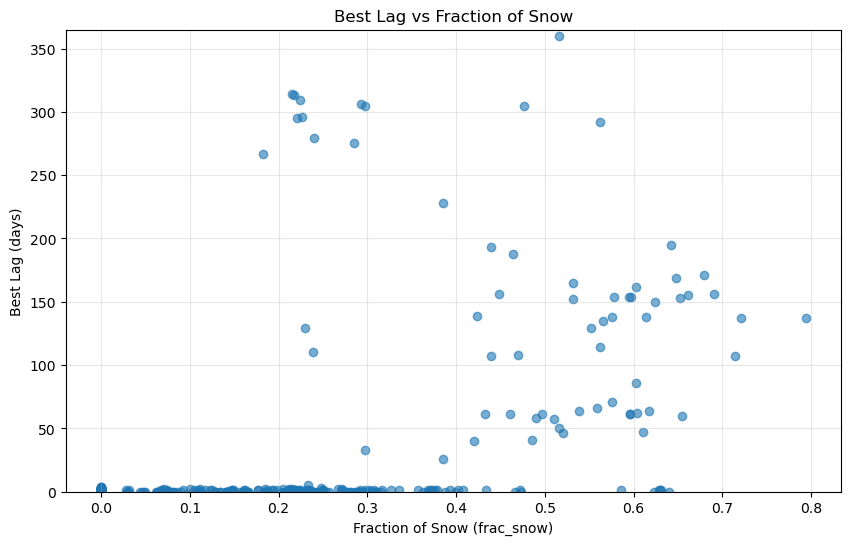

In [10]:
plt.figure(figsize=(10, 6))
plt.scatter(df_results_us['frac_snow'], df_results_us['best_lag'], alpha=0.6)
plt.xlabel('Fraction of Snow (frac_snow)')
plt.ylabel('Best Lag (days)')
plt.title('Best Lag vs Fraction of Snow')
plt.ylim(0, 365)
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
# Split into rain vs snow dominated
rain_dominated = df_results_us[df_results_us['frac_snow'] < 0.3]
snow_dominated = df_results_us[df_results_us['frac_snow'] > 0.5]

print(f"Rain-dominated correlation: {rain_dominated['correlation'].mean():.3f}")
print(f"Snow-dominated correlation: {snow_dominated['correlation'].mean():.3f}")

Rain-dominated correlation: 0.448
Snow-dominated correlation: 0.046


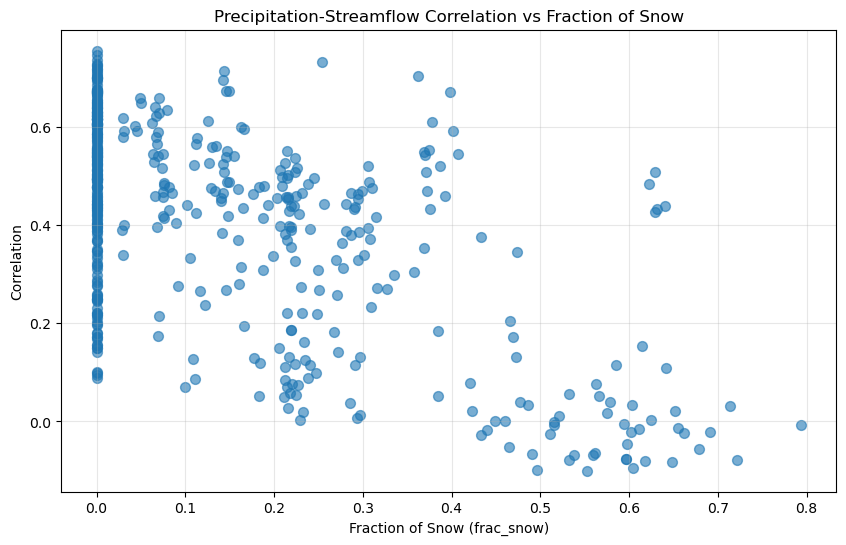

In [12]:
plt.figure(figsize=(10, 6))
plt.scatter(df_results_us['frac_snow'], df_results_us['correlation'], alpha=0.6, s=50)
plt.xlabel('Fraction of Snow (frac_snow)')
plt.ylabel('Correlation')
plt.title('Precipitation-Streamflow Correlation vs Fraction of Snow')
plt.grid(True, alpha=0.3)
plt.show()

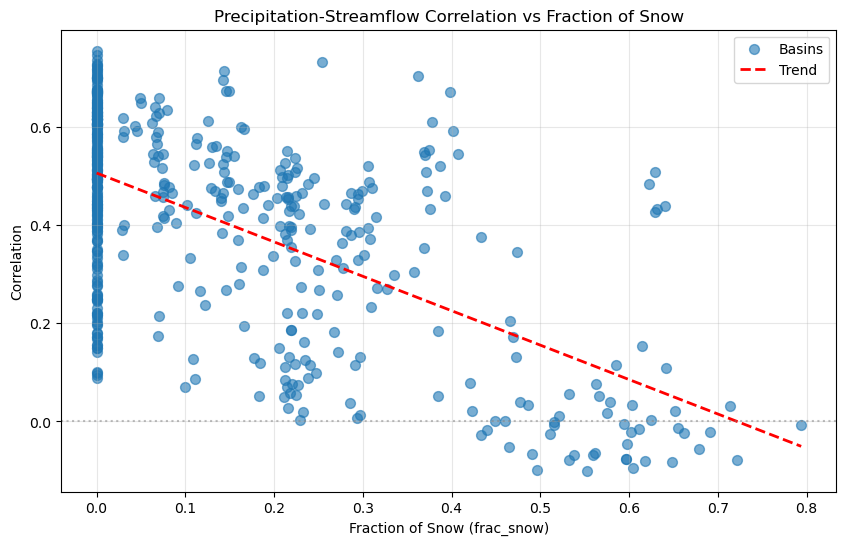

In [13]:
plt.figure(figsize=(10, 6))
plt.scatter(df_results_us['frac_snow'], df_results_us['correlation'], alpha=0.6, s=50, label='Basins')

# Add trend line
valid_data = df_results_us.dropna(subset=['frac_snow', 'correlation'])
z = np.polyfit(valid_data['frac_snow'], valid_data['correlation'], 1)
p = np.poly1d(z)
x_trend = np.linspace(valid_data['frac_snow'].min(), valid_data['frac_snow'].max(), 100)
plt.plot(x_trend, p(x_trend), "r--", linewidth=2, label='Trend')

plt.xlabel('Fraction of Snow (frac_snow)')
plt.ylabel('Correlation')
plt.title('Precipitation-Streamflow Correlation vs Fraction of Snow')
plt.axhline(y=0, color='gray', linestyle=':', alpha=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Peak lag

In [14]:
# PEAK LAG

from scipy.signal import find_peaks

PRECIP_COLS_US = {
    "camels": "camels_precipitation",
}
GAUGE_COL_US = "streamflow"

peak_lag_results_us = []

for basin_name in basins:
    basin_id = basin_name

    try:
        ds = xr.open_dataset(time_series / f"{basin_name}.nc")
        ds = ds.sel(date=slice(DATE_START, DATE_END))

        obs: DataArray = ds[GAUGE_COL_US]

        for product_name, col in PRECIP_COLS_US.items():
            if col not in ds:
                print(f"  Skipping {product_name} for {basin_id}: column not found")
                continue

            sim: DataArray = ds[col]
            row = {"basin": basin_id, "product": product_name}

            try:
                precip = sim.values
                streamflow = obs.values
                
                # Remove NaNs for peak detection
                valid_idx = ~(np.isnan(precip) | np.isnan(streamflow))
                precip_clean = precip[valid_idx]
                streamflow_clean = streamflow[valid_idx]
                
                # p95 = np.percentile(precip_clean, 75)
                # precip_peaks, _ = find_peaks(precip_clean, height=p95)

                # s95 = np.percentile(streamflow_clean, 75)
                # streamflow_peaks, _ = find_peaks(streamflow_clean, height=s95)

                percentile = 80
                precip_threshold = np.percentile(precip_clean, percentile)
                precip_peaks, _ = find_peaks(precip_clean, distance=100, height=precip_threshold)

                streamflow_threshold = np.percentile(streamflow_clean, percentile)
                streamflow_peaks, _ = find_peaks(streamflow_clean, distance=100, height=streamflow_threshold)
                
                if len(precip_peaks) > 0 and len(streamflow_peaks) > 0:
                    # For each precip peak, find closest streamflow peak
                    lags = []
                    for pp in precip_peaks:
                        closest_sp = streamflow_peaks[np.argmin(np.abs(streamflow_peaks - pp))]
                        lag = closest_sp - pp
                        if 0 <= lag <= 365:
                            lags.append(lag)
                    
                    row["peak_lag"] = np.mean(lags) if lags else np.nan
                else:
                    row["peak_lag"] = np.nan
                    
            except Exception as e:
                row["peak_lag"] = np.nan
                print(f"  peak_lag failed ({basin_id}, {product_name}): {e}")

            peak_lag_results_us.append(row)

    except Exception as e:
        print(f"Skipping {basin_id}: {e}")

df_peak_lag_results_us = pd.DataFrame(peak_lag_results_us)

In [15]:
df_peak_lag_results_us

,basin,product,peak_lag
0,camels_01022500,camels,29.404255
1,camels_01031500,camels,22.375000
2,camels_01047000,camels,24.672727
3,camels_01052500,camels,34.333333
4,camels_01054200,camels,20.480769
...,...,...,...
526,camels_11482500,camels,33.208333
527,camels_11522500,camels,32.500000
528,camels_11523200,camels,43.785714
529,camels_11528700,camels,60.785714


In [16]:
df_peak_lag_results_us = df_peak_lag_results_us.merge(
    attributes[['gauge_id', 'frac_snow']], 
    left_on='basin', 
    right_on='gauge_id', 
    how='left'
)

df_peak_lag_results_us.head()

,basin,product,peak_lag,gauge_id,frac_snow
0,camels_01022500,camels,29.404255,camels_01022500,0.335440
1,camels_01031500,camels,22.375000,camels_01031500,0.306273
2,camels_01047000,camels,24.672727,camels_01047000,0.299063
3,camels_01052500,camels,34.333333,camels_01052500,0.368406
4,camels_01054200,camels,20.480769,camels_01054200,0.374272


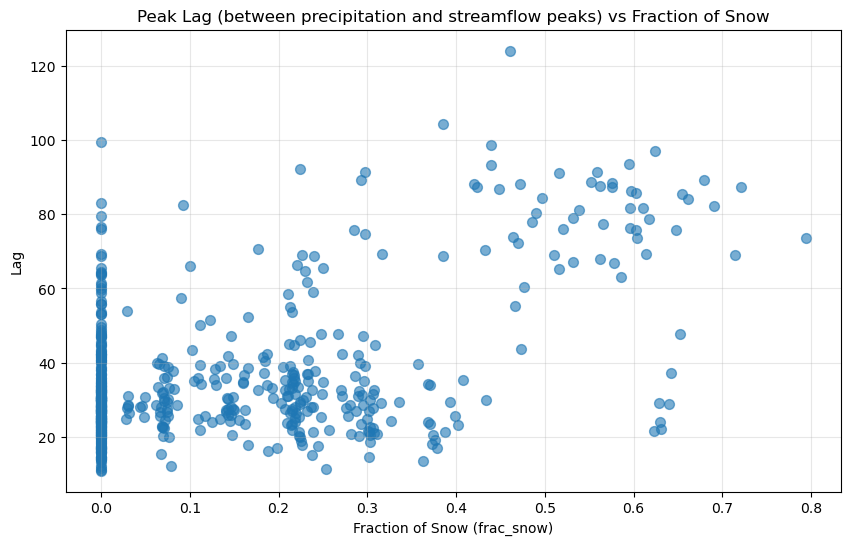

In [17]:
plt.figure(figsize=(10, 6))
plt.scatter(df_peak_lag_results_us['frac_snow'], df_peak_lag_results_us['peak_lag'], alpha=0.6, s=50)
plt.xlabel('Fraction of Snow (frac_snow)')
plt.ylabel('Lag')
plt.title('Peak Lag (between precipitation and streamflow peaks) vs Fraction of Snow')
plt.grid(True, alpha=0.3)
plt.show()

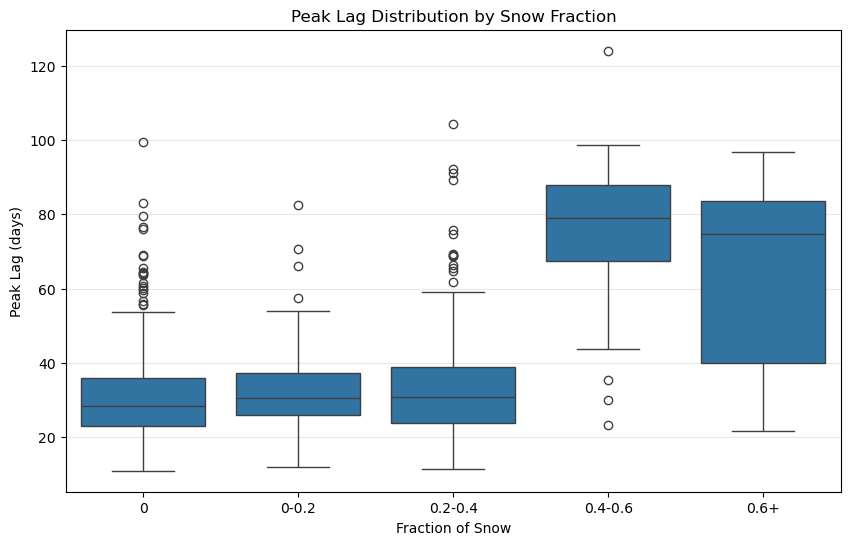

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Separate 0 from (0, 0.2]
def bin_snow(frac):
    if frac == 0:
        return '0'
    elif frac <= 0.2:
        return '0-0.2'
    elif frac <= 0.4:
        return '0.2-0.4'
    elif frac <= 0.6:
        return '0.4-0.6'
    else:
        return '0.6+'

df_peak_lag_results_us['snow_bin'] = df_peak_lag_results_us['frac_snow'].apply(bin_snow)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_peak_lag_results_us, x='snow_bin', y='peak_lag', 
            order=['0', '0-0.2', '0.2-0.4', '0.4-0.6', '0.6+'])
plt.xlabel('Fraction of Snow')
plt.ylabel('Peak Lag (days)')
plt.title('Peak Lag Distribution by Snow Fraction')
plt.grid(True, alpha=0.3, axis='y')
plt.show()

In [19]:
ensemble_camels_metrics = pd.read_csv(camels_metrics_dir)
ensemble_camels_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01022500,0.873195,0.788830,0.888161,0.862428,0.898171,0.937404,0.931892,-0.063178,-8.366964,-3.287585,21.083689,0.181818,0.218750,23.027092
1,camels_01031500,0.888100,1.148055,1.071473,0.849362,0.859370,0.946412,0.993412,-0.004485,-13.875319,-9.154499,43.207787,0.181818,0.121212,27.374205
2,camels_01047000,0.875006,1.496363,1.223259,0.856017,0.875586,0.937855,0.962715,-0.026249,-12.341771,-3.645504,-7.947985,0.090909,0.324324,23.634581
3,camels_01052500,0.885470,1.410681,1.187721,0.891121,0.997709,0.944424,1.093598,0.060219,-1.528729,-5.378186,28.173573,0.083333,0.184211,26.958374
4,camels_01054200,0.657618,11.366599,3.371439,0.594510,0.635551,0.836159,0.931040,-0.036060,-36.622028,-4.827666,-7.782070,0.250000,0.210526,44.101734


In [20]:
df_peak_lag_results_us = df_peak_lag_results_us.merge(
    ensemble_camels_metrics[['basin_id', 'NSE']], 
    left_on='basin', 
    right_on='basin_id',
    how='left'
)

df_peak_lag_results_us.head()

,basin,product,peak_lag,gauge_id,frac_snow,snow_bin,basin_id,NSE
0,camels_01022500,camels,29.404255,camels_01022500,0.335440,0.2-0.4,camels_01022500,0.873195
1,camels_01031500,camels,22.375000,camels_01031500,0.306273,0.2-0.4,camels_01031500,0.888100
2,camels_01047000,camels,24.672727,camels_01047000,0.299063,0.2-0.4,camels_01047000,0.875006
3,camels_01052500,camels,34.333333,camels_01052500,0.368406,0.2-0.4,camels_01052500,0.885470
4,camels_01054200,camels,20.480769,camels_01054200,0.374272,0.2-0.4,camels_01054200,0.657618


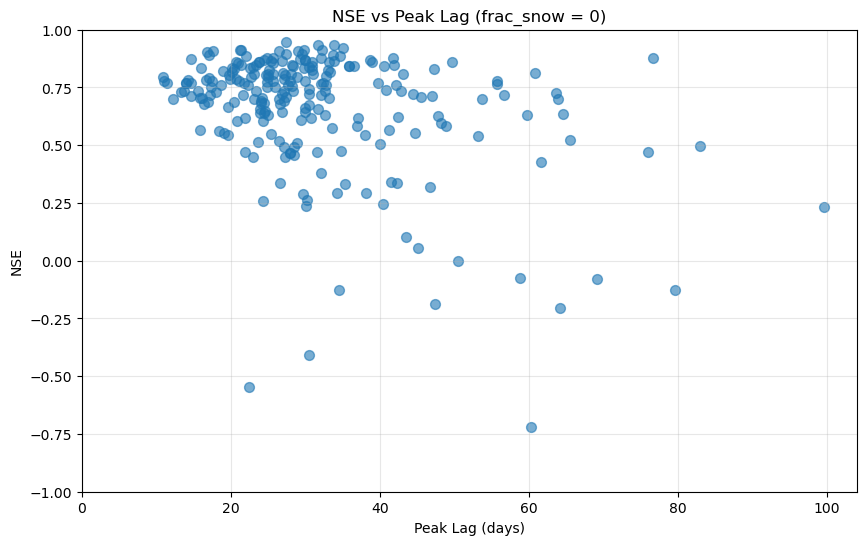

In [21]:
# Filter for frac_snow = 0
df_zero_snow = df_peak_lag_results_us[df_peak_lag_results_us['frac_snow'] == 0]

plt.figure(figsize=(10, 6))
plt.scatter(df_zero_snow['peak_lag'], df_zero_snow['NSE'], alpha=0.6, s=50)
plt.xlabel('Peak Lag (days)')
plt.ylabel('NSE')
plt.title('NSE vs Peak Lag (frac_snow = 0)')
plt.grid(True, alpha=0.3)
plt.ylim(-1, 1)
plt.xlim(left=0)
plt.show()

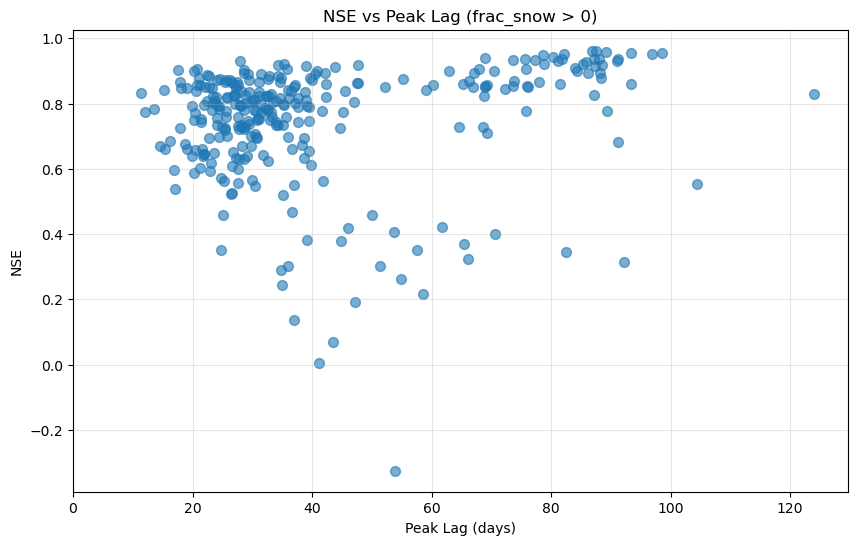

In [22]:
# Filter for frac_snow > 0
df_nonzero_snow = df_peak_lag_results_us[df_peak_lag_results_us['frac_snow'] > 0]

plt.figure(figsize=(10, 6))
plt.scatter(df_nonzero_snow['peak_lag'], df_nonzero_snow['NSE'], alpha=0.6, s=50)
plt.xlabel('Peak Lag (days)')
plt.ylabel('NSE')
plt.title('NSE vs Peak Lag (frac_snow > 0)')
plt.grid(True, alpha=0.3)
plt.xlim(left=0)
plt.show()

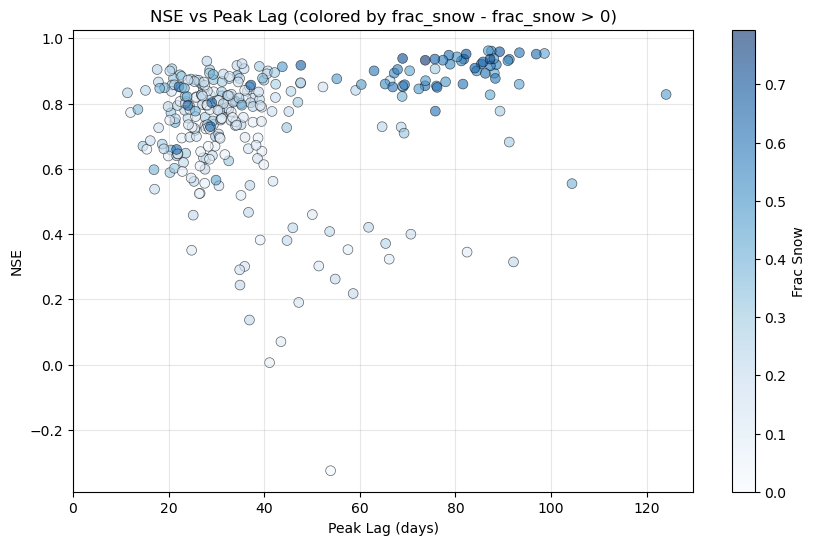

In [27]:
# Filter for frac_snow > 0
df_nonzero_snow = df_peak_lag_results_us[df_peak_lag_results_us['frac_snow'] > 0]

plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_nonzero_snow['peak_lag'], df_nonzero_snow['NSE'], 
                      c=df_nonzero_snow['frac_snow'],  # Color by frac_snow
                      alpha=0.6, s=50, cmap='Blues',  # viridis is a good colormap
                      edgecolors='black', linewidth=0.5, vmin=0)

plt.xlabel('Peak Lag (days)')
plt.ylabel('NSE')
plt.title('NSE vs Peak Lag (colored by frac_snow - frac_snow > 0)')
plt.grid(True, alpha=0.3)
plt.xlim(left=0)
plt.colorbar(scatter, label='Frac Snow')  # Add colorbar legend
plt.show()

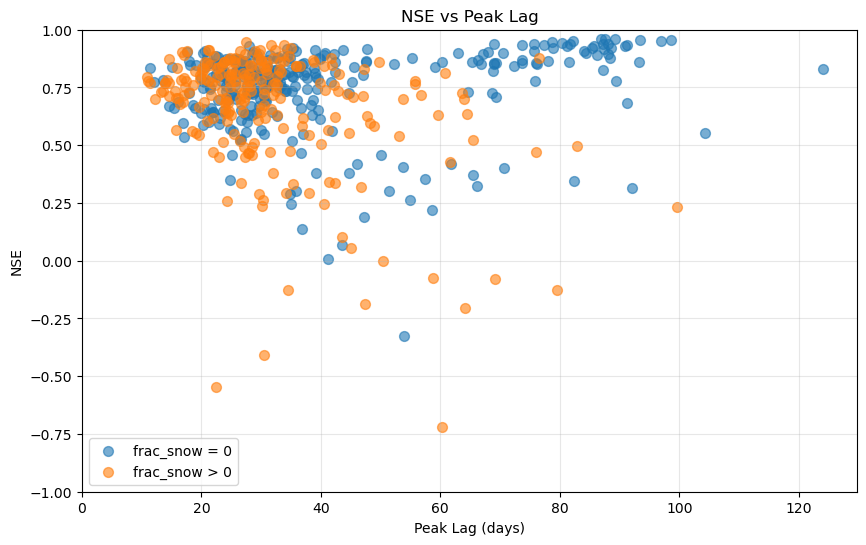

In [24]:
plt.figure(figsize=(10, 6))
plt.scatter(df_nonzero_snow['peak_lag'], df_nonzero_snow['NSE'], alpha=0.6, s=50, label='frac_snow = 0')
plt.scatter(df_zero_snow['peak_lag'], df_zero_snow['NSE'], alpha=0.6, s=50, label='frac_snow > 0')
plt.xlabel('Peak Lag (days)')
plt.ylabel('NSE')
plt.title('NSE vs Peak Lag')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(-1, 1)
plt.xlim(left=0)
plt.show()

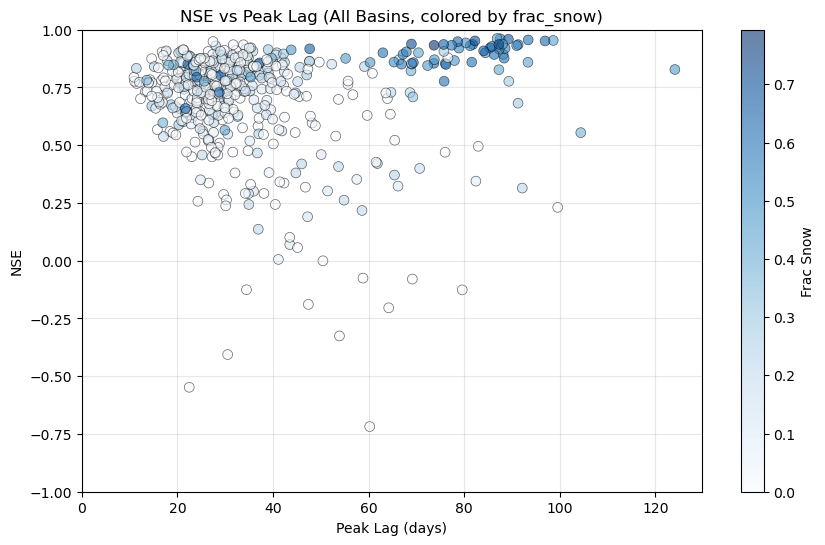

In [26]:
# Use all data (no frac_snow filter)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_peak_lag_results_us['peak_lag'], df_peak_lag_results_us['NSE'], 
                      c=df_peak_lag_results_us['frac_snow'],  # Color by frac_snow
                      alpha=0.6, s=50, cmap='Blues',
                      edgecolors='black', linewidth=0.5)

plt.xlabel('Peak Lag (days)')
plt.ylabel('NSE')
plt.title('NSE vs Peak Lag (All Basins, colored by frac_snow)')
plt.grid(True, alpha=0.3)
plt.xlim(left=0)
plt.ylim(-1, 1)
plt.colorbar(scatter, label='Frac Snow')
plt.show()

# Month of mean maximum streamflow and precipitation

In [10]:
# # import numpy as np
# # import pandas as pd
# # import xarray as xr
# # from xarray import DataArray
# # from pathlib import Path

# # # Configuration
# # time_series = Path("path/to/your/data")  # Update this path
# DATE_START = "1980-01-01"
# DATE_END = "2014-12-31"

# PRECIP_COLS_US = {
#     "camels": "camels_precipitation",
# }
# GAUGE_COL_US = "streamflow"

# # basins = ["01013500", "01022500"]  # Update with your basin IDs

# monthly_peaks_results_us = []

# for basin_name in basins:
#     basin_id = basin_name

#     try:
#         ds = xr.open_dataset(time_series / f"{basin_name}.nc")
#         ds = ds.sel(date=slice(DATE_START, DATE_END))

#         obs: DataArray = ds[GAUGE_COL_US]

#         for product_name, col in PRECIP_COLS_US.items():
#             if col not in ds:
#                 print(f"  Skipping {product_name} for {basin_id}: column not found")
#                 continue

#             sim: DataArray = ds[col]
#             row = {"basin": basin_id, "product": product_name}

#             try:
#                 precip = sim.values
#                 streamflow = obs.values
#                 dates = ds["date"].values
                
#                 # Create DataFrame with dates and values
#                 df = pd.DataFrame({
#                     "date": dates,
#                     "precip": precip,
#                     "streamflow": streamflow
#                 })
#                 df["date"] = pd.to_datetime(df["date"])
                
#                 # Extract month from date
#                 df["month"] = df["date"].dt.month
#                 df["month_name"] = df["date"].dt.strftime("%B")
                
#                 # Remove NaNs
#                 df_clean = df.dropna(subset=["precip", "streamflow"])
                
#                 if len(df_clean) == 0:
#                     row["precip_peak_month"] = np.nan
#                     row["precip_peak_month_name"] = np.nan
#                     row["streamflow_peak_month"] = np.nan
#                     row["streamflow_peak_month_name"] = np.nan
#                 else:
#                     # Create monthly time series first
#                     df_monthly = df_clean.set_index("date").resample("MS").agg({
#                         "precip": "sum",           # Total precip per month
#                         "streamflow": "mean"       # Mean streamflow per month
#                     }).reset_index()
                    
#                     # Extract calendar month
#                     df_monthly["month"] = df_monthly["date"].dt.month
                    
#                     # Compute mean across all years for each calendar month
#                     precip_by_month = df_monthly.groupby("month")["precip"].mean()
#                     precip_peak_month = precip_by_month.idxmax()
#                     precip_peak_month_name = pd.to_datetime(f"2000-{int(precip_peak_month):02d}-01").strftime("%B")
                    
#                     row["precip_peak_month"] = int(precip_peak_month)
#                     row["precip_peak_month_name"] = precip_peak_month_name
                    
#                     streamflow_by_month = df_monthly.groupby("month")["streamflow"].mean()
#                     streamflow_peak_month = streamflow_by_month.idxmax()
#                     streamflow_peak_month_name = pd.to_datetime(f"2000-{int(streamflow_peak_month):02d}-01").strftime("%B")
                    
#                     row["streamflow_peak_month"] = int(streamflow_peak_month)
#                     row["streamflow_peak_month_name"] = streamflow_peak_month_name
                    
#             except Exception as e:
#                 row["precip_peak_month"] = np.nan
#                 row["precip_peak_month_name"] = np.nan
#                 row["streamflow_peak_month"] = np.nan
#                 row["streamflow_peak_month_name"] = np.nan
#                 print(f"  monthly_peaks failed ({basin_id}, {product_name}): {e}")

#             monthly_peaks_results_us.append(row)

#     except Exception as e:
#         print(f"Skipping {basin_id}: {e}")

# df_monthly_peaks_results_us = pd.DataFrame(monthly_peaks_results_us)
# print(df_monthly_peaks_results_us)

# # Optional: Save to CSV
# df_monthly_peaks_results_us.to_csv("monthly_peaks_results.csv", index=False)

In [8]:
df_monthly_peaks_results_us = pd.read_csv("monthly_peaks_results.csv")

In [9]:
df_monthly_peaks_results_us = df_monthly_peaks_results_us.merge(
    attributes[['gauge_id', 'frac_snow']], 
    left_on='basin', 
    right_on='gauge_id', 
    how='left'
)

In [10]:
df_monthly_peaks_results_us.head()

,basin,product,precip_peak_month,precip_peak_month_name,streamflow_peak_month,streamflow_peak_month_name,gauge_id,frac_snow
0,camels_01022500,camels,11,November,4,April,camels_01022500,0.335440
1,camels_01031500,camels,6,June,4,April,camels_01031500,0.306273
2,camels_01047000,camels,6,June,4,April,camels_01047000,0.299063
3,camels_01052500,camels,6,June,4,April,camels_01052500,0.368406
4,camels_01054200,camels,10,October,4,April,camels_01054200,0.374272


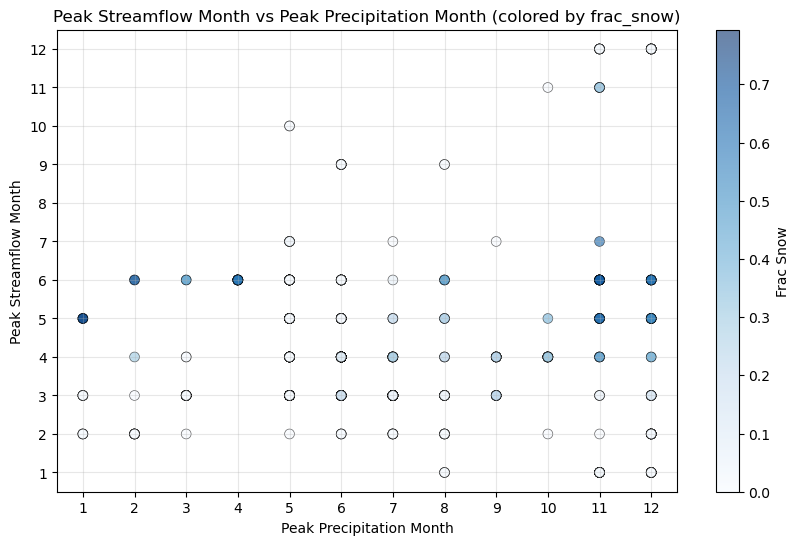

In [11]:
# Scatter plot: Streamflow peak month vs Precipitation peak month
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_monthly_peaks_results_us['precip_peak_month'], 
                      df_monthly_peaks_results_us['streamflow_peak_month'], 
                      c=df_monthly_peaks_results_us['frac_snow'],  # Color by frac_snow
                      alpha=0.6, s=50, cmap='Blues',
                      edgecolors='black', linewidth=0.5)

plt.xlabel('Peak Precipitation Month')
plt.ylabel('Peak Streamflow Month')
plt.title('Peak Streamflow Month vs Peak Precipitation Month (colored by frac_snow)')
plt.grid(True, alpha=0.3)

# Set x and y axis to show months 1-12
plt.xlim(0.5, 12.5)
plt.ylim(0.5, 12.5)
plt.xticks(range(1, 13))
plt.yticks(range(1, 13))

plt.colorbar(scatter, label='Frac Snow')
plt.show()

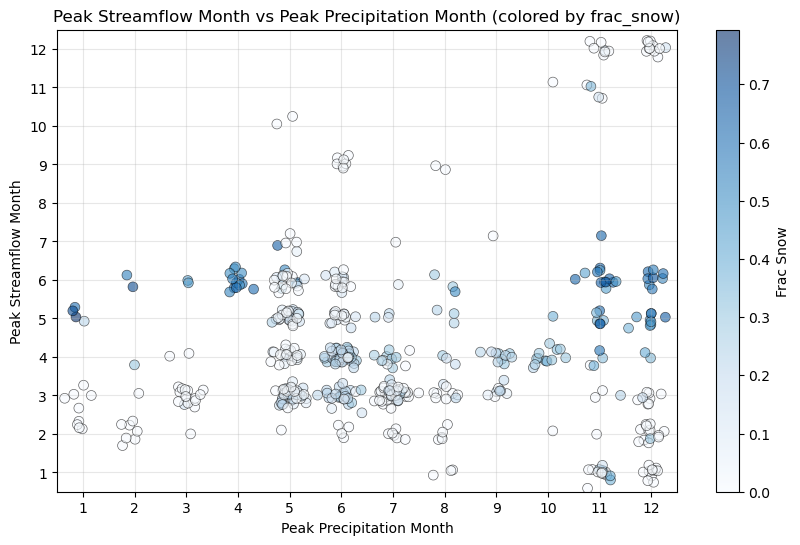

In [14]:
plt.figure(figsize=(10, 6))

# Add random jitter to avoid overlapping points
jitter_amount = 0.15  # Adjust this value (0.05 to 0.15 works well)
x_jitter = df_monthly_peaks_results_us['precip_peak_month'] + np.random.normal(0, jitter_amount, len(df_monthly_peaks_results_us))
y_jitter = df_monthly_peaks_results_us['streamflow_peak_month'] + np.random.normal(0, jitter_amount, len(df_monthly_peaks_results_us))

scatter = plt.scatter(x_jitter, y_jitter,
                      c=df_monthly_peaks_results_us['frac_snow'],
                      alpha=0.6, s=50, cmap='Blues',
                      edgecolors='black', linewidth=0.5)

plt.xlabel('Peak Precipitation Month')
plt.ylabel('Peak Streamflow Month')
plt.title('Peak Streamflow Month vs Peak Precipitation Month (colored by frac_snow)')
plt.grid(True, alpha=0.3)
plt.xlim(0.5, 12.5)
plt.ylim(0.5, 12.5)
plt.xticks(range(1, 13))
plt.yticks(range(1, 13))
plt.colorbar(scatter, label='Frac Snow')
plt.show()

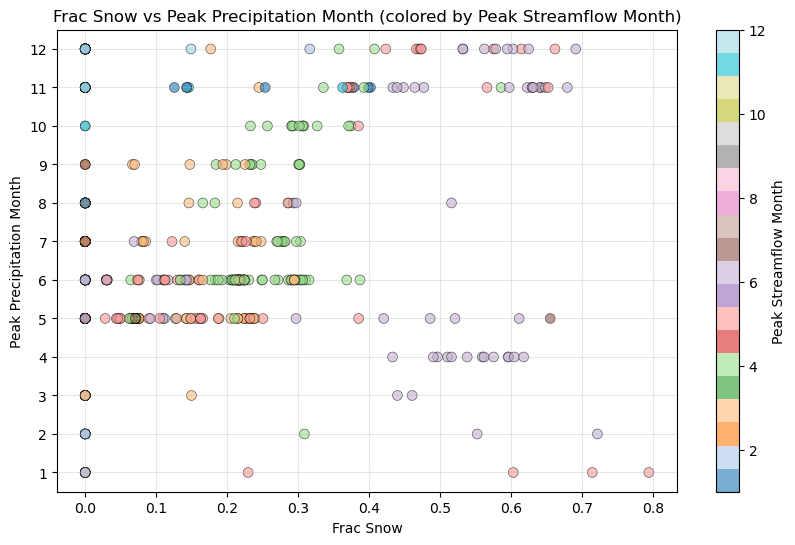

In [13]:
# Scatter plot: Frac Snow vs Peak Precipitation Month (colored by Peak Streamflow Month)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_monthly_peaks_results_us['frac_snow'],  # ← X-axis: Frac Snow
                      df_monthly_peaks_results_us['precip_peak_month'],  # Y-axis: Peak Precip Month
                      c=df_monthly_peaks_results_us['streamflow_peak_month'],  # Color by streamflow peak month
                      alpha=0.6, s=50, cmap='tab20',
                      edgecolors='black', linewidth=0.5)

plt.xlabel('Frac Snow')
plt.ylabel('Peak Precipitation Month')
plt.title('Frac Snow vs Peak Precipitation Month (colored by Peak Streamflow Month)')
plt.grid(True, alpha=0.3)

# Set y-axis to show months 1-12
plt.ylim(0.5, 12.5)
plt.yticks(range(1, 13))

plt.colorbar(scatter, label='Peak Streamflow Month')
plt.show()